# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Aarón Martínez Garcidueñas  
**Grupo:** 511  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# escalador de desviacion estandar
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# payment type 2 es cash, hay que usar ese

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")
df.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


In [2]:
print("Dimensiones:", df.shape)
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

df.info()
df.describe().round(2)

Dimensiones: (2427612, 20)

Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_con

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415487.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,1.17,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,0.46,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,1.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,1.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,4.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


In [3]:
print(df["payment_type"].value_counts(dropna=False))

payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [4]:
df_limpio = df.copy()

print("Dimensiones antes:", df_limpio.shape)
print("\nNulos por columna:")
print(df_limpio.isnull().sum())
print("\nRegistros duplicados:", df_limpio.duplicated().sum())

Dimensiones antes: (2427612, 20)

Nulos por columna:
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Registros duplicados: 11961


In [5]:
# Duplicados y nulos
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()
print("Después de quitar duplicados y nulos:", df_limpio.shape)

Después de quitar duplicados y nulos: (2196158, 20)


In [6]:
# Condiciones
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
].copy()

print("Dimensiones después de limpiar:", df_limpio.shape)
print("Nulos restantes:", df_limpio.isnull().sum().sum())
print("Duplicados restantes:", df_limpio.duplicated().sum())

Dimensiones después de limpiar: (2096600, 20)
Nulos restantes: 0
Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [7]:
mapa_pago = {1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}
df_limpio["payment_type"] = df_limpio["payment_type"].map(mapa_pago)
print(df_limpio["payment_type"].value_counts())

payment_type
Credit card    1799462
Cash            282085
Dispute           9753
No charge         5300
Name: count, dtype: int64


In [8]:
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()

X = df_cash[["passenger_count", "trip_distance"]].copy()

print("Viajes en efectivo:", len(df_cash))
X.describe().round(2)

Viajes en efectivo: 282085


,passenger_count,trip_distance
count,282085.00,282085.00
mean,1.34,3.84
std,0.76,6.21
min,1.00,0.01
25%,1.00,0.92
50%,1.00,1.70
75%,1.00,4.37
max,6.00,1686.49


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [9]:
X_log = np.log1p(X)

escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

In [10]:
print("Resumen de X_log (log1p):")
display(X_log.describe().round(3))

X_escalado_df = pd.DataFrame(X_escalado, columns=["passenger_count", "trip_distance"], index=X.index)
print("Resumen de X_escalado (estandarizado):")
display(X_escalado_df.describe().round(3))

Resumen de X_log (log1p):


,passenger_count,trip_distance
count,282085.000,282085.000
mean,0.815,1.225
std,0.250,0.763
min,0.693,0.010
25%,0.693,0.652
50%,0.693,0.993
75%,0.693,1.681
max,1.946,7.431


Resumen de X_escalado (estandarizado):


,passenger_count,trip_distance
count,282085.000,282085.000
mean,-0.000,-0.000
std,1.000,1.000
min,-0.486,-1.592
25%,-0.486,-0.751
50%,-0.486,-0.304
75%,-0.486,0.597
max,4.520,8.130


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [17]:
valores_k = range(2, 7)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas,
                                     sample_size=5000, random_state=42))

resultados = pd.DataFrame({"k": list(valores_k), "Inercia": inercias, "Silueta": siluetas})
display(resultados.round(4))

,k,Inercia,Silueta
0,2,324581.9399,0.5503
1,3,160363.1884,0.6117
2,4,115075.5831,0.6202
3,5,86895.8983,0.6249
4,6,61144.8891,0.5617


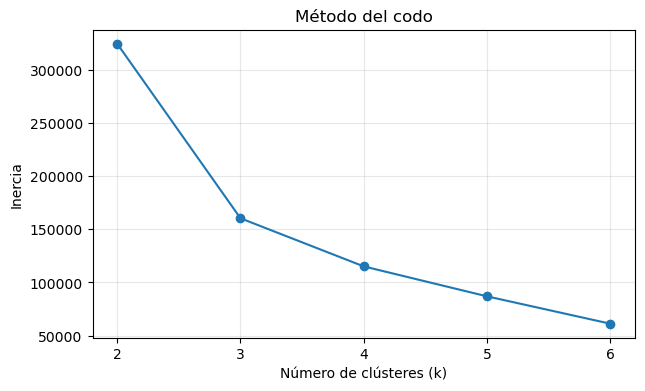

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(resultados["k"], resultados["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

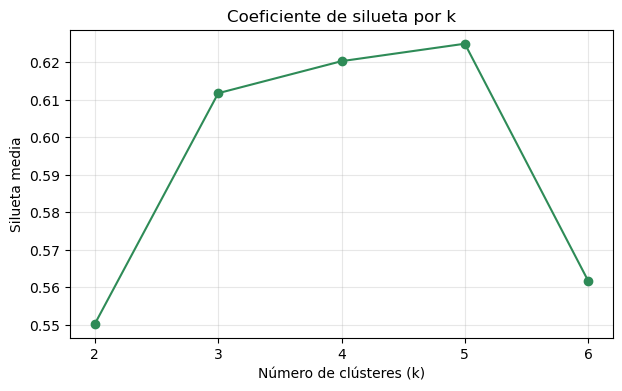

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(resultados["k"], resultados["Silueta"], marker="o", color="seagreen")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta media")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

In [14]:
k_final = 4

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_
print("Viajes por clúster:", np.bincount(etiquetas))

Viajes por clúster: [160372  59946  18849  42918]


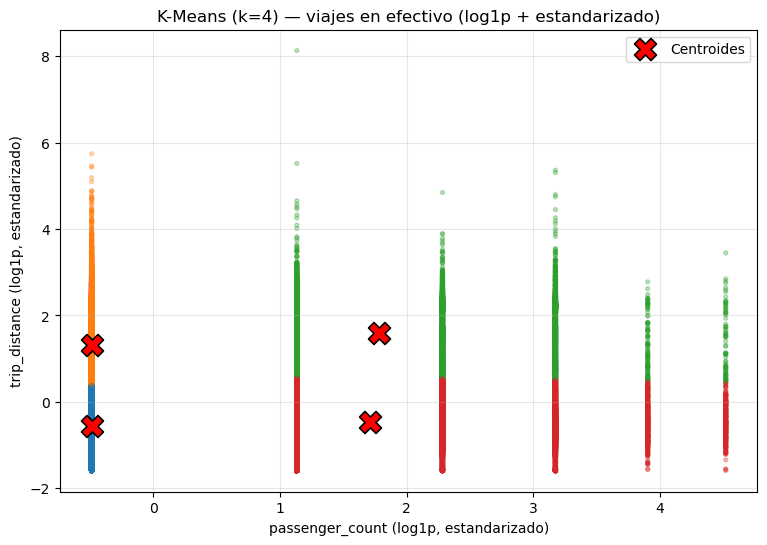

In [15]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_escalado[:, 0], X_escalado[:, 1],
                      c=etiquetas, cmap="tab10", s=8, alpha=0.3,
                      vmin=-0.5, vmax=9.5)
plt.scatter(centroides[:, 0], centroides[:, 1],
            color="red", marker="X", s=250, edgecolor="black", linewidth=1.2,
            label="Centroides")
plt.title(f"K-Means (k={k_final}) — viajes en efectivo (log1p + estandarizado)")
plt.xlabel("passenger_count (log1p, estandarizado)")
plt.ylabel("trip_distance (log1p, estandarizado)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [16]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

tabla = df_resultado.groupby("cluster").agg(
    viajes=("cluster", "size"),
    pasajeros_media=("passenger_count", "mean"),
    pasajeros_mediana=("passenger_count", "median"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
).round(2)

display(tabla)

,viajes,pasajeros_media,pasajeros_mediana,distancia_media_millas,distancia_mediana_millas
cluster,,,,,
0,160372,1.00,1.0,1.36,1.20
1,59946,1.00,1.0,9.55,7.96
2,18849,2.62,2.0,12.08,10.37
3,42918,2.55,2.0,1.53,1.30


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí k = 4. La inercia siempre baja al aumentar k, de 324,582 en k = 2 a 61,145 en k = 6, así que por sí sola no decide; el codo se aplana por ahí de k = 3 – 4 y la silueta sube de 0.550 ken  = 2 a 0.612 en k = 3 y 0.620 en k = 4, llegando a su máximo en k = 5 con 0.625 con una mejora de apenas 0.005, y cae a 0.562 en k = 6. Con k = 4 la silueta es casi la máxima y obtengo grupos claros e interpretables, por lo que es más simple que k = 5.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** 

Las identifiqué así:

- Solitarios de corta distancia son 160 mil viajes, el más grande. mediana 1 pasajero, mediana 1.2 millas el viaje típico urbano.

- Solitarios de larga distancia: son 60,000, mediana de 1 pasajero y 8 millas.

- Grupos pequeños de corta distancia:Son unos 43,000. Media de 2.55 pasajeros, mediana de 2 pasajeros y 1.3 millas

- Grupos de larga distancia: 19,000 aprox, el grupo más pequeño. La media es de 2.6 pasajeros, mediana de 2 pasajeros y de 10.4 millas, media de 12 millas.

**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** Los grupos de un pasajero concentran la mayoría de los viajes. Entre los de más pasajeros, la distancia depende del grupo. Tener más pasajeros no significa que la distancia sea mayor.


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** No siempre. El grupo de 2.55 pasajeros recorre solo 1.3 millas de mediana, parecido a los solitarios cortos de 1.2 millas. Los solitarios largos, de hecho, recorren más millas que los grupos cortos con más pasajeros. SOlo el grupo de viajes largos con 2.6 pasajeros combina ambas. No existe una relación general como tal, existen viajes cortos y largos tanto para uno como para más pasajeros.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**